In [26]:
from pathlib import Path
import matplotlib.pyplot as plt

import random
import numpy as np
import pandas as pd
import torch

GLOBAL_SEED = 420
random.seed(GLOBAL_SEED)
np.random.seed(GLOBAL_SEED)
torch.manual_seed(GLOBAL_SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(GLOBAL_SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = True
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [ ]:
# hiperparameters
embedding_dim = 6
epochs = 20

In [28]:
dataset = Path("dataset.txt").read_text(encoding="utf-8")
dataset

'mip likes dax\nmip likes zof\n\ntig likes dax\ntig likes zof\n\nral owns tek\nral owns mek\n\nred is color\nblue is color\ngreen is color\n\ncat is animal\ndog is animal\nbird is animal'

In [29]:
sentences = [line.split() for line in dataset.splitlines() if line.strip()]
word_columns = [f"word_{i}" for i in range(1, max(map(len, sentences)) + 1)]
sentence_table = pd.DataFrame(sentences, columns=word_columns)
sentence_table


,word_1,word_2,word_3
0,mip,likes,dax
1,mip,likes,zof
2,tig,likes,dax
3,tig,likes,zof
4,ral,owns,tek
5,ral,owns,mek
6,red,is,color
7,blue,is,color
8,green,is,color
9,cat,is,animal


In [30]:
# create a vocabulary of unique words
vocabulary = sorted({word for sentence in sentences for word in sentence})
vocab_size = len(vocabulary)
print(f"Vocabulary size: {vocab_size}")
print(f"Vocabulary: {vocabulary}")

Vocabulary size: 18
Vocabulary: ['animal', 'bird', 'blue', 'cat', 'color', 'dax', 'dog', 'green', 'is', 'likes', 'mek', 'mip', 'owns', 'ral', 'red', 'tek', 'tig', 'zof']


In [31]:
vocabulary = list(vocabulary)
def encode(text):
    return [vocabulary.index(word) for word in text.split()]
def decode(indices):
    return " ".join(vocabulary[i] for i in indices)

print(encode("blue is color"))
print(decode(encode("blue is color")))

[2, 8, 4]
blue is color


In [32]:
class MaskedSelfAttention(torch.nn.Module):
    def __init__(self, embedding_dim):
        super().__init__()
        self.kqv = torch.nn.Linear(embedding_dim, embedding_dim * 3, bias=False)

    def forward(self, x):
        B, T, C = x.shape
        kqv = self.kqv(x)  # (B, T, 3 * C)
        k, q, v = kqv.chunk(3, dim=-1)  # (B, T, C) each
        
        # compute attention scores
        mask = torch.triu(torch.ones(T, T, device=x.device), diagonal=1).bool()  # (T, T)
        attn_scores = (q @ k.transpose(-2, -1)) * (C ** -0.5)  # (B, T, T)
        attn_scores = attn_scores.masked_fill(mask, float('-inf'))  #(B, T, T)
        attn_weights = torch.nn.functional.softmax(attn_scores, dim=-1)  # (B, T, T)
        return attn_weights @ v  # (B, T, C)


class SmallWordPredictor(torch.nn.Module):
    def __init__(self, vocab_size, embedding_dim):
        super().__init__()
        self.embedding = torch.nn.Embedding(vocab_size, embedding_dim)

        self.attention = MaskedSelfAttention(embedding_dim)
        
        self.ln1 = torch.nn.Linear(embedding_dim, 2 * embedding_dim)
        self.gelu = torch.nn.GELU()
        self.ln2 = torch.nn.Linear(2 * embedding_dim, embedding_dim)
        
        self.out_projection = torch.nn.Linear(embedding_dim, vocab_size, bias=False)
        self.out_projection.weight = self.embedding.weight  # weight tying

    def forward(self, x):
        x = self.embedding(x)  # (B, T, C)
        x = x + self.attention(x)  # (B, T, C)
        x = x + self.ln2(self.gelu(self.ln1(x)))  # (B, T, C)
        return self.out_projection(x)  # (B, T, vocab_size)

In [33]:
# take first two words as x and last two words as y for training
x = torch.tensor([encode(" ".join(words)) for words in sentence_table.iloc[:, :2].to_numpy()], dtype=torch.long)
y = torch.tensor([encode(" ".join(words)) for words in sentence_table.iloc[:, -2:].to_numpy()], dtype=torch.long)
x = x.to(device)
y = y.to(device)
print(x[0], y[0])

tensor([11,  9], device='cuda:0') tensor([9, 5], device='cuda:0')


In [34]:
model = SmallWordPredictor(vocab_size, embedding_dim).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-2)
model = model.to(device)

print(model)
print(f"Number of parameters: {sum(p.numel() for p in model.parameters())}")

SmallWordPredictor(
  (embedding): Embedding(18, 6)
  (attention): MaskedSelfAttention(
    (kqv): Linear(in_features=6, out_features=18, bias=False)
  )
  (ln1): Linear(in_features=6, out_features=12, bias=True)
  (gelu): GELU(approximate='none')
  (ln2): Linear(in_features=12, out_features=6, bias=True)
  (out_projection): Linear(in_features=6, out_features=18, bias=False)
)
Number of parameters: 378


In [35]:
# visualize paiwise cosine similarity of word embeddings
def visualize_embeddings(model, vocabulary):
    embeddings = model.embedding.weight.data.cpu().numpy()
    cosine_similarities = np.dot(embeddings, embeddings.T)
    norms = np.linalg.norm(embeddings, axis=1)
    cosine_similarities /= norms[:, None]
    cosine_similarities /= norms[None, :]
    
    plt.figure(figsize=(10, 8))
    plt.imshow(cosine_similarities, cmap='viridis', interpolation='nearest')
    plt.colorbar()
    plt.xticks(ticks=np.arange(len(vocabulary)), labels=vocabulary, rotation=90)
    plt.yticks(ticks=np.arange(len(vocabulary)), labels=vocabulary)
    plt.title("Pairwise Cosine Similarity of Word Embeddings")
    plt.show()

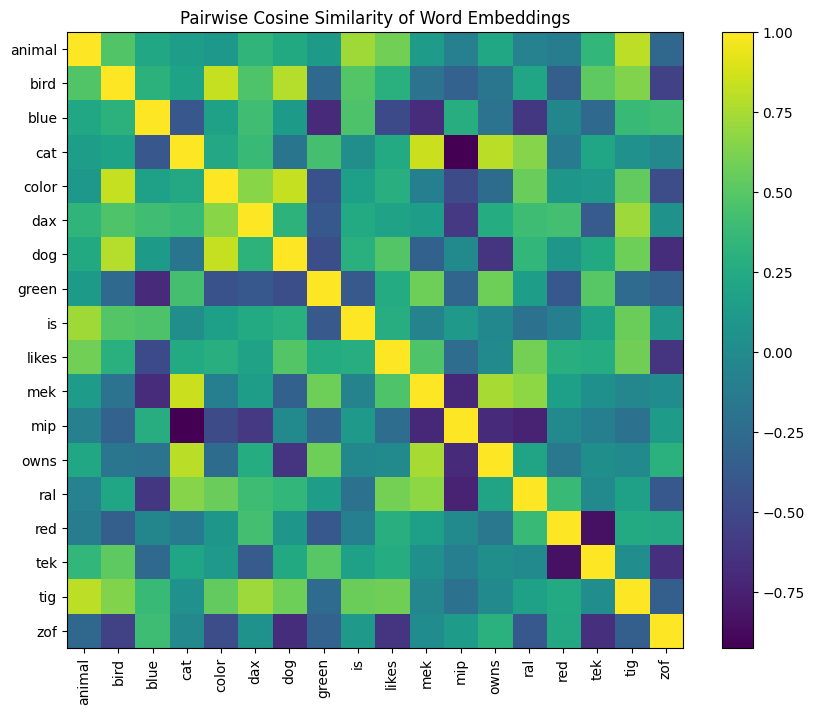

Epoch 0, Loss: 6.1512
Epoch 1, Loss: 5.7220
Epoch 2, Loss: 5.3313
Epoch 3, Loss: 4.9732
Epoch 4, Loss: 4.6433
Epoch 5, Loss: 4.3389
Epoch 6, Loss: 4.0587
Epoch 7, Loss: 3.8019
Epoch 8, Loss: 3.5674
Epoch 9, Loss: 3.3541
Epoch 10, Loss: 3.1603
Epoch 11, Loss: 2.9848
Epoch 12, Loss: 2.8263
Epoch 13, Loss: 2.6834
Epoch 14, Loss: 2.5547
Epoch 15, Loss: 2.4392
Epoch 16, Loss: 2.3363
Epoch 17, Loss: 2.2463
Epoch 18, Loss: 2.1684
Epoch 19, Loss: 2.0995
Epoch 20, Loss: 2.0343
Epoch 21, Loss: 1.9681
Epoch 22, Loss: 1.8989
Epoch 23, Loss: 1.8276
Epoch 24, Loss: 1.7567
Epoch 25, Loss: 1.6896
Epoch 26, Loss: 1.6285
Epoch 27, Loss: 1.5740
Epoch 28, Loss: 1.5249
Epoch 29, Loss: 1.4787
Epoch 30, Loss: 1.4331
Epoch 31, Loss: 1.3865
Epoch 32, Loss: 1.3384
Epoch 33, Loss: 1.2892
Epoch 34, Loss: 1.2403
Epoch 35, Loss: 1.1932
Epoch 36, Loss: 1.1492
Epoch 37, Loss: 1.1089
Epoch 38, Loss: 1.0723
Epoch 39, Loss: 1.0382
Epoch 40, Loss: 1.0053
Epoch 41, Loss: 0.9727
Epoch 42, Loss: 0.9404
Epoch 43, Loss: 0.909

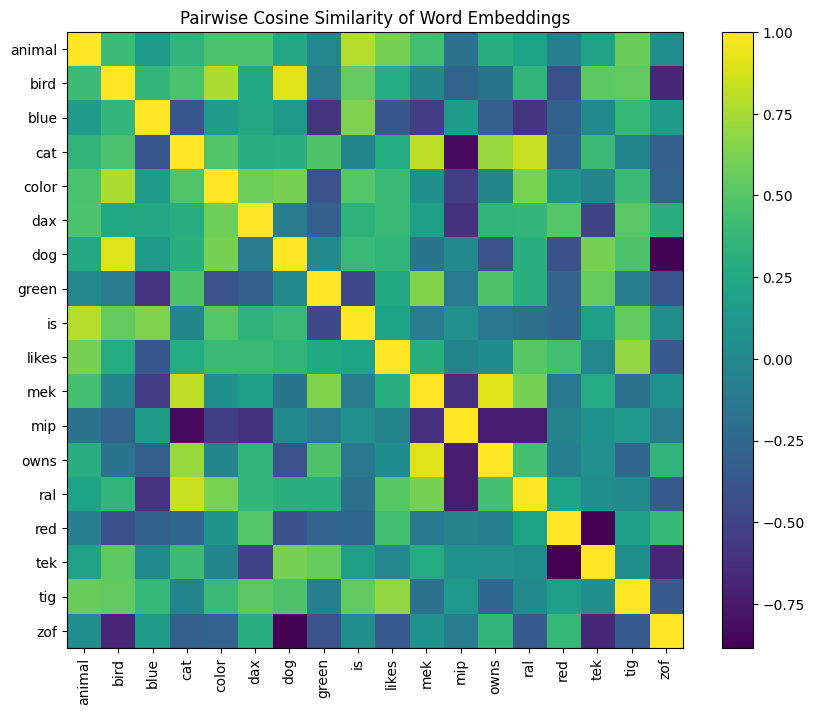

Epoch 50, Loss: 0.7404
Epoch 51, Loss: 0.7214
Epoch 52, Loss: 0.7038
Epoch 53, Loss: 0.6875
Epoch 54, Loss: 0.6722
Epoch 55, Loss: 0.6575
Epoch 56, Loss: 0.6427
Epoch 57, Loss: 0.6277
Epoch 58, Loss: 0.6124
Epoch 59, Loss: 0.5973
Epoch 60, Loss: 0.5829
Epoch 61, Loss: 0.5688
Epoch 62, Loss: 0.5549
Epoch 63, Loss: 0.5406
Epoch 64, Loss: 0.5261
Epoch 65, Loss: 0.5117
Epoch 66, Loss: 0.4976
Epoch 67, Loss: 0.4837
Epoch 68, Loss: 0.4699
Epoch 69, Loss: 0.4559
Epoch 70, Loss: 0.4422
Epoch 71, Loss: 0.4292
Epoch 72, Loss: 0.4171
Epoch 73, Loss: 0.4059
Epoch 74, Loss: 0.3957
Epoch 75, Loss: 0.3864
Epoch 76, Loss: 0.3782
Epoch 77, Loss: 0.3710
Epoch 78, Loss: 0.3645
Epoch 79, Loss: 0.3582
Epoch 80, Loss: 0.3518
Epoch 81, Loss: 0.3451
Epoch 82, Loss: 0.3379
Epoch 83, Loss: 0.3301
Epoch 84, Loss: 0.3217
Epoch 85, Loss: 0.3124
Epoch 86, Loss: 0.3023
Epoch 87, Loss: 0.2915
Epoch 88, Loss: 0.2803
Epoch 89, Loss: 0.2696
Epoch 90, Loss: 0.2607
Epoch 91, Loss: 0.2541
Epoch 92, Loss: 0.2487
Epoch 93, L

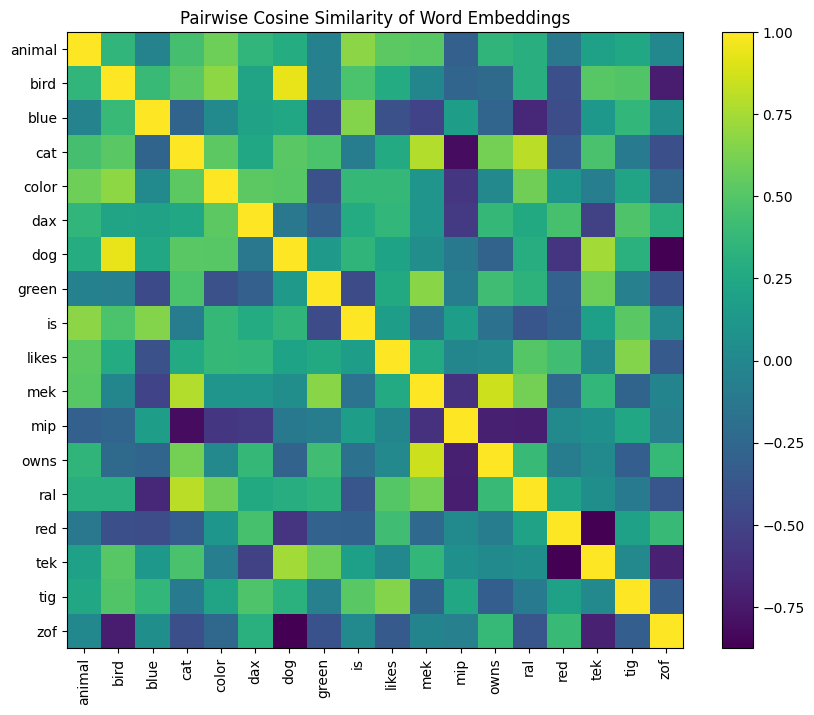

Epoch 100, Loss: 0.2100
Epoch 101, Loss: 0.2063
Epoch 102, Loss: 0.2034
Epoch 103, Loss: 0.2010
Epoch 104, Loss: 0.1987
Epoch 105, Loss: 0.1966
Epoch 106, Loss: 0.1945
Epoch 107, Loss: 0.1926
Epoch 108, Loss: 0.1910
Epoch 109, Loss: 0.1896
Epoch 110, Loss: 0.1885
Epoch 111, Loss: 0.1876
Epoch 112, Loss: 0.1868
Epoch 113, Loss: 0.1859
Epoch 114, Loss: 0.1852
Epoch 115, Loss: 0.1844
Epoch 116, Loss: 0.1837
Epoch 117, Loss: 0.1831
Epoch 118, Loss: 0.1826
Epoch 119, Loss: 0.1821
Epoch 120, Loss: 0.1817
Epoch 121, Loss: 0.1813
Epoch 122, Loss: 0.1809
Epoch 123, Loss: 0.1805
Epoch 124, Loss: 0.1802
Epoch 125, Loss: 0.1799
Epoch 126, Loss: 0.1796
Epoch 127, Loss: 0.1793
Epoch 128, Loss: 0.1791
Epoch 129, Loss: 0.1789
Epoch 130, Loss: 0.1787
Epoch 131, Loss: 0.1786
Epoch 132, Loss: 0.1784
Epoch 133, Loss: 0.1782
Epoch 134, Loss: 0.1781
Epoch 135, Loss: 0.1779
Epoch 136, Loss: 0.1778
Epoch 137, Loss: 0.1777
Epoch 138, Loss: 0.1776
Epoch 139, Loss: 0.1774
Epoch 140, Loss: 0.1773
Epoch 141, Loss:

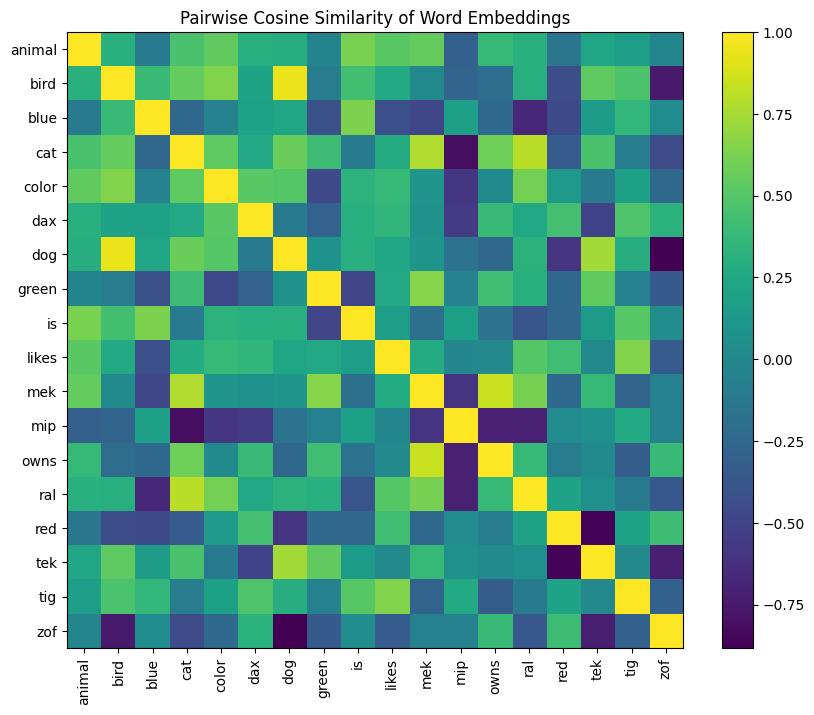

Epoch 150, Loss: 0.1765
Epoch 151, Loss: 0.1764
Epoch 152, Loss: 0.1764
Epoch 153, Loss: 0.1763
Epoch 154, Loss: 0.1763
Epoch 155, Loss: 0.1762
Epoch 156, Loss: 0.1762
Epoch 157, Loss: 0.1761
Epoch 158, Loss: 0.1761
Epoch 159, Loss: 0.1760
Epoch 160, Loss: 0.1760
Epoch 161, Loss: 0.1759
Epoch 162, Loss: 0.1759
Epoch 163, Loss: 0.1758
Epoch 164, Loss: 0.1758
Epoch 165, Loss: 0.1758
Epoch 166, Loss: 0.1757
Epoch 167, Loss: 0.1757
Epoch 168, Loss: 0.1756
Epoch 169, Loss: 0.1756
Epoch 170, Loss: 0.1756
Epoch 171, Loss: 0.1755
Epoch 172, Loss: 0.1755
Epoch 173, Loss: 0.1755
Epoch 174, Loss: 0.1754
Epoch 175, Loss: 0.1754
Epoch 176, Loss: 0.1754
Epoch 177, Loss: 0.1754
Epoch 178, Loss: 0.1753
Epoch 179, Loss: 0.1753
Epoch 180, Loss: 0.1753
Epoch 181, Loss: 0.1753
Epoch 182, Loss: 0.1752
Epoch 183, Loss: 0.1752
Epoch 184, Loss: 0.1752
Epoch 185, Loss: 0.1752
Epoch 186, Loss: 0.1751
Epoch 187, Loss: 0.1751
Epoch 188, Loss: 0.1751
Epoch 189, Loss: 0.1751
Epoch 190, Loss: 0.1750
Epoch 191, Loss:

In [ ]:
# training loop, one batch in entire dataset
for epoch in range(epochs):
    optimizer.zero_grad()
    logits = model(x)  # (B, T, vocab_size)
    loss = torch.nn.functional.cross_entropy(logits.view(-1, vocab_size), y.view(-1))
    loss.backward()
    optimizer.step()

    if epoch % 50 == 0:
        with torch.no_grad():
            visualize_embeddings(model, vocabulary)
    print(f"Epoch {epoch}, Loss: {loss.item():.4f}")

Too many layers, they can be trained to predict the input accurately without needing to really train embeddings. As visible by the cosine simmilarity, the embeddings change very little. Should create a model with only the embedding, mapping one embedding into simmilar.